# Task 2: Visualizing fire scars through false color

Author: Veronica Moran

https://github.com/veronica-moran/eds220-hwk4.git

# About

## Purpose

This notebook uses Landsat 8 satellite imagery and fire perimeter data to visualize the Palisades and Eaton fire scars. These fires occurred in Los Angeles County in January 2025. False color imagery is used to highlight burned areas against surrounding vegetation.

## Highlights

- Cleaning the fire perimeter data to make it easier to work with, filtering data and creating a new dataframe with only the most recent Palisades and Eaton fire perimeters.
- Cleaning Landsat data by restoring spatial information, adjusting scale to get true color image, and setting null values to 0.
- Reprojecting the fire perimeter data to match CRS of Landsat data.
- Creating a false-color map using shortwave infrared, near-infrared, and red bands on the Landsat data and overlaying fire perimeters.

## About the data

Simplified collection of bands (red, green, blue, near-infrared and shortwave infrared) from the Landsat Collection 2 Level-2 atmospherically corrected surface reflectance data, collected by the Landsat 8 satellite. Retrieved from the [Microsoft Planetary Computer data catalog](https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2) and clipped to an area surrounding the fire perimeters, the data was accessed as landsat8-2025-02-23-palisades-eaton.nc in the course shared data [Google Drive](https://drive.google.com/drive/u/1/folders/1USqhiMLyN8GE05B8WJmHabviJGnmAsLP).

The second dataset contains fire perimeters for the Eaton and Palisades fires. The data was retrieved from the [AVIRIS Data Portal](https://popo.jpl.nasa.gov/mmgis-aviris/?mission=LA_Fires). Most recent fire perimeter was from January 12, 2025. The data was accessed November 15, 2026.

## References

[1] Microsoft Planetary Computer. Landsat Collection 2 Level-2. Accessed November 15, 2026. https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2

[2] NASA Jet Propulsion Laboratory. AVIRIS data portal: LA fires. Accessed November 15, 2026. https://popo.jpl.nasa.gov/mmgis-aviris/?mission=LA_Fires

[3] Riebeek, H. (2014, March 14). Why is that forest red and that cloud blue? How to interpret a false-color satellite image. NASA Earth Observatory. https://science.nasa.gov/earth/earth-observatory/how-to-interpret-a-false-color-satellite-image/

[4] Galaz García, C. EDS 220: Working with Environmental Datasets. Master of Environmental Data Science, Bren School of Environmental Science & Management, UC Santa Barbara. Accessed November 15, 2026. https://meds-eds-220.github.io/MEDS-eds-220-course/

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import xarray as xr
import rioxarray
import matplotlib.patheffects as pe

In [2]:
# Read fire perimeters
fp = os.path.join('data', 'fire_perimeters.geojson')
perimeters = gpd.read_file(fp)

# Read Landsat imagery
fp = os.path.join('data', 'landsat8-2025-02-23-palisades-eaton.nc')
bands = xr.open_dataset(fp)


sh: 1: getfattr: not found


# Fire Perimeter Data Exploration

In [3]:
perimeters.head()

,name,acres,created,Shape__Are,Shape__Len,source,dateTime,_,geometry
0,AUTO,55.7,1736839224000,3.305966e+05,3633.829649,FIRIS,2025-01-14 07:20:24+00:00,"{'idx': 34, 'end_time': '1736839224000'}","MULTIPOLYGON (((-119.21282 34.23610, -119.2128..."
1,PALISADES,23706.6,1736686649000,1.401755e+08,129483.127792,INTEL FLIGHT DATA,2025-01-12 12:57:29+00:00,"{'idx': 33, 'end_time': '1736686649000'}","MULTIPOLYGON (((-118.60006 34.08394, -118.6000..."
2,Eaton,14005.4,1736686830000,8.306198e+07,101455.890112,INTEL FLIGHT DATA,2025-01-12 13:00:30+00:00,"{'idx': 32, 'end_time': '1736686830000'}","MULTIPOLYGON (((-118.13628 34.17676, -118.1366..."
3,Palisades,23713.4,1736707013000,1.402157e+08,129567.976023,INTEL FLIGHT DATA,2025-01-12 18:36:53+00:00,"{'idx': 31, 'end_time': '1736707013000'}","MULTIPOLYGON (((-118.60006 34.08394, -118.6000..."
4,Eaton,13991.6,1736622854000,8.298039e+07,101053.743729,INTEL FLIGHT DATA,2025-01-11 19:14:14+00:00,"{'idx': 30, 'end_time': '1736622854000'}","MULTIPOLYGON (((-118.13628 34.17676, -118.1366..."


In [4]:
# Checking column names, non-null count and dtype
perimeters.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 34 entries, 0 to 33
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype              
---  ------      --------------  -----              
 0   name        34 non-null     object             
 1   acres       34 non-null     object             
 2   created     34 non-null     int64              
 3   Shape__Are  34 non-null     float64            
 4   Shape__Len  34 non-null     float64            
 5   source      34 non-null     object             
 6   dateTime    34 non-null     datetime64[ns, UTC]
 7   _           34 non-null     object             
 8   geometry    34 non-null     geometry           
dtypes: datetime64[ns, UTC](1), float64(2), geometry(1), int64(1), object(4)
memory usage: 2.5+ KB


In [5]:
# Checking if the CRS is geographic
print(perimeters.crs.is_geographic)

# Checking if the CRS is projected
print(perimeters.crs.is_projected)

# Checking CRS
perimeters.crs

True
False


<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [6]:
# Checking unique fire names
perimeters['name'].unique()

array(['AUTO', 'PALISADES', 'Eaton', 'Palisades', 'EATON', 'ARCHER',
       'KENNETH', 'HURST', 'LIDIA', 'SUNSET', 'UNK'], dtype=object)

The fire perimeter dataset contains 34 rows and 9 columns, with no missing values. The data include fire names, acreage, perimeter area and length, data sources, observation dates, and fire perimeter geometries. There are 11 unique name values, which represent eight known fires and one unknown fire, with inconsistent capitalization for the Palisades and Eaton fires. The acres column dtype is an object, instead of numeric. The CRS is WGS 84 (EPSG:4326), a geographic reference system.

In [7]:
# Plotting the fire perimeters
perimeters.plot()

<Axes: >

# Perimeters Data Cleaning

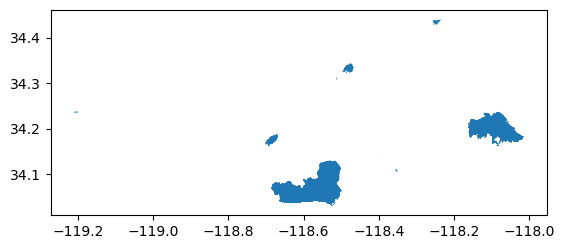

In [8]:
# Updating name column to lowercase fire names 
perimeters['name'] = perimeters['name'].str.lower()

In [9]:
# Updating columns to lowercase and replace double underscore with single underscore
perimeters.columns = perimeters.columns.str.lower().str.replace('__', '_')

In [10]:
# Filtering to palisades and eaton fires, sorting by newest date
perimeters = perimeters[
    perimeters['name'].isin(['palisades', 'eaton'])
].sort_values('datetime', ascending = False)

# Grouping by fire name, creating new dataframe with newest perimeter for each fire
palisades_eaton = perimeters.groupby('name').head(1).reset_index(drop=True)

palisades_eaton

,name,acres,created,shape_are,shape_len,source,datetime,_,geometry
0,palisades,23713.4,1736707013000,1.402157e+08,129567.976023,INTEL FLIGHT DATA,2025-01-12 18:36:53+00:00,"{'idx': 31, 'end_time': '1736707013000'}","MULTIPOLYGON (((-118.60006 34.08394, -118.6000..."
1,eaton,14005.4,1736686830000,8.306198e+07,101455.890112,INTEL FLIGHT DATA,2025-01-12 13:00:30+00:00,"{'idx': 32, 'end_time': '1736686830000'}","MULTIPOLYGON (((-118.13628 34.17676, -118.1366..."


<Axes: >

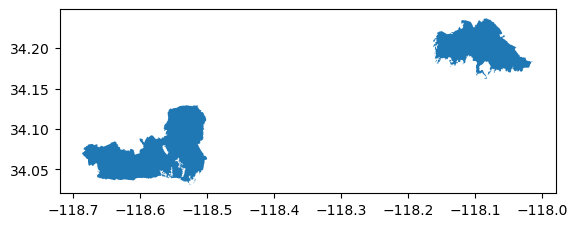

In [11]:
# Plotting fire perimeters

palisades_eaton.plot()

# NetCDF Data Exploration

In [12]:
# Checking bands information
bands

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

The Landsat dataset contains five spectral bands: red, green, blue, near-infrared (nir08), and shortwave infrared (swir22). Each band contains 3,888,156 values stored as float32. Spatial dimensions are y (1,418 rows) and x (2,742 columns). The x and y coordinates units are in meters, with a spatial resolution of 30 meters. The CRS is WGS 84 / UTM zone 11N (EPSG:32611), which is a projected coordinate reference system.

# Restoring Spatial Information

In [13]:
# Checking bands CRS
print(bands.rio.crs)

None


Landsat data is geospatial, but the CRS is not defined.

In [14]:
# Printing CRS
print(bands.spatial_ref.crs_wkt)

PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


In [15]:
# Recovering geospatial information
bands = bands.rio.write_crs(bands.spatial_ref.crs_wkt)

print(bands.rio.crs)

EPSG:32611


# True Color Image

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


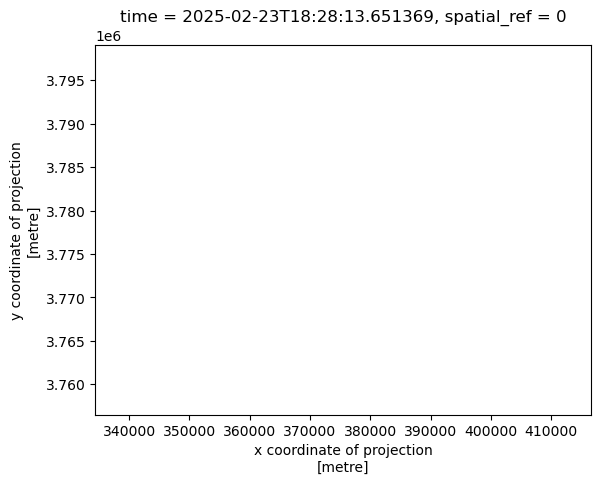

In [16]:
# Converting data to dataarray() and plotting
bands[['red', 'green', 'blue']].to_dataarray().plot.imshow()
plt.show()

/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


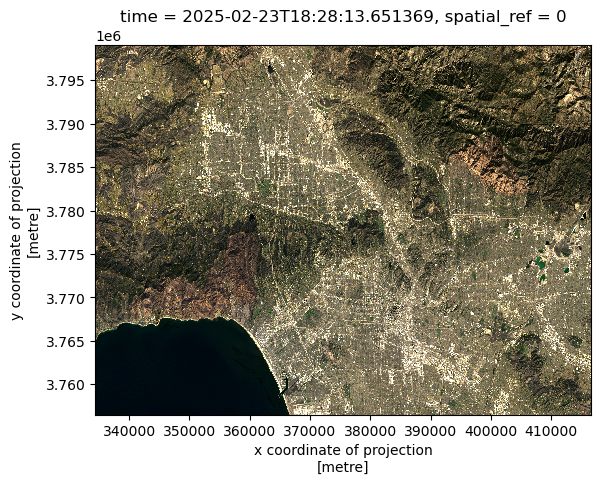

In [17]:
# Converting data to dataarray() and plotting
bands[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust = True)
plt.show()

In [18]:
# Checking null value count
bands.isnull().sum()

<xarray.Dataset> Size: 56B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          int64 8B 0
    green        int64 8B 1
    blue         int64 8B 109
    nir08        int64 8B 0
    swir22       int64 8B 0

The blue band has 109 NaN values and the green band has 1, which causes the warning.

In [19]:
# Replacing null values with 0
bands = bands.fillna(0)

In [20]:
bands.isnull().sum()

<xarray.Dataset> Size: 56B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          int64 8B 0
    green        int64 8B 0
    blue         int64 8B 0
    nir08        int64 8B 0
    swir22       int64 8B 0

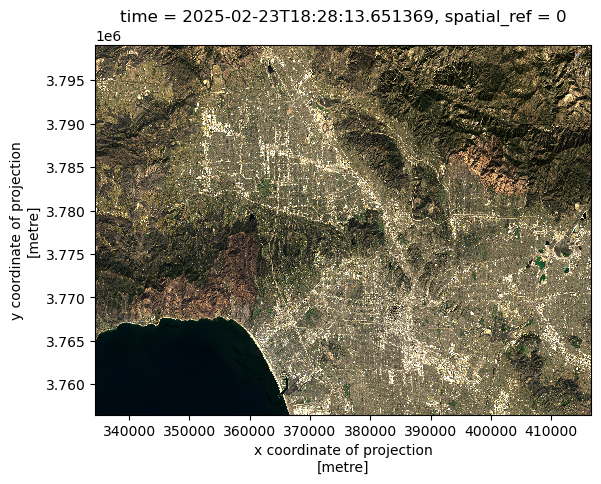

In [21]:
# Plotting true color image red, green and blue bands
bands[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust = True)
plt.show()

In part (a), the image appears white because the RGB values are outside of the range that is accepted by imshow(). After using robust= True, the color scaling is adjusted and the image displays correctly. Replacing NaN values with 0 removes the missing values warning.

# False Color Image

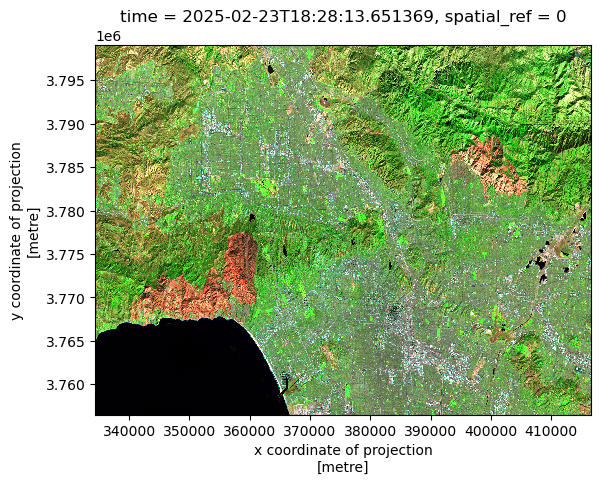

In [22]:
# Plotting false color image, shortwave infrared, near-infrared, red
falsecolor = bands[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(robust = True)

plt.show()

# Map: Palisades and Eaton Fire Burn Scars

In [23]:
# Reprojecting perimeter data to match bands data CRS
palisades_eaton = palisades_eaton.to_crs(bands.rio.crs)
assert palisades_eaton.crs == bands.rio.crs

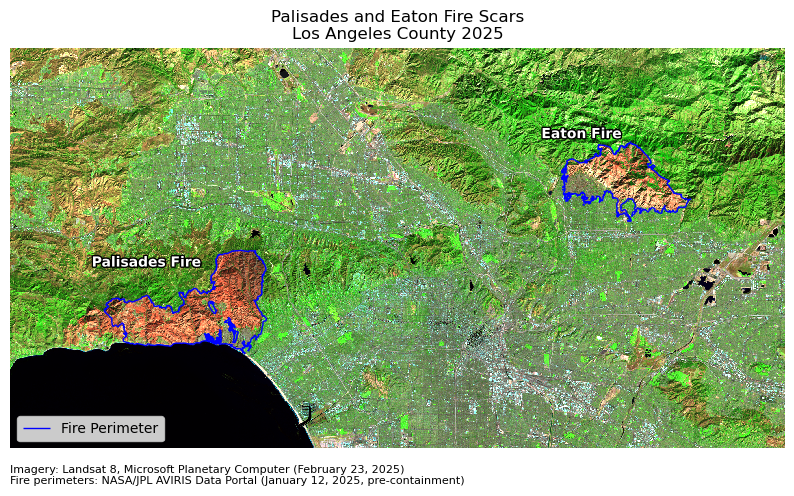

In [24]:
# Plotting raster and perimeters
fig, ax = plt.subplots(figsize=(10, 8))
ax.axis('off')

# Plotting raster
bands[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(ax=ax,robust = True)

# Plotting Perimeter
palisades_eaton.boundary.plot(ax=ax,
                edgecolor='blue',
                linewidth=1,
                label = 'Fire Perimeter')

# Adding title
ax.set_title('Palisades and Eaton Fire Scars\nLos Angeles County 2025')

# Adding legend
ax.legend(loc='lower left')


# Adding fire names as text annotations
for x, y, name in zip(palisades_eaton.geometry.centroid.x,
                      palisades_eaton.geometry.centroid.y,
                      palisades_eaton['name']):
    ax.text(x, y + 4500, name.title() + ' Fire',
            fontsize=10,
            color='white',
            fontweight='bold',
            ha='right',
           path_effects=[
               pe.withStroke(linewidth=2,
                             foreground='black')
            ])
    
# Adding data sources
ax.text(0, -0.04,
        'Imagery: Landsat 8, Microsoft Planetary Computer (February 23, 2025)\n'
        'Fire perimeters: NASA/JPL AVIRIS Data Portal (January 12, 2025, pre-containment)',
        transform=ax.transAxes,
        fontsize=8,
        va='top')

plt.show()

Palisades and Eaton fire scars, outlined in blue, are shown using false-color Landsat 8 imagery. Shortwave infrared (SWIR), near-infrared (NIR), and red bands are displayed in the red, green and blue channels to highlight differences in land cover. SWIR is strongly absorbed by water and moisture in leaves. When vegetation is burned or removed, exposed soil and burned areas reflect more SWIR and less NIR. Healthy vegetation strongly reflects NIR and due to chlorophyll strongly absorbs red light. These differences in how land cover absorbs or reflects light cause burn scars to appear red or rust colored, healthy vegetation to appear bright green, and water to appear black or dark blue[3].